# **Entrega 2 proyecto integrador  | Grupo 5k10 - 10**
Integrantes: Belén Castillo, Agustín Expósito, Macarena Epifani, Sol Falabella, Sergio Farías y Tomás Camacho

**Proyecto:** F1 Strategy Pipeline

**Objetivo del proyecto:**  
Determinar si conviene entrar a boxes a cambiar el compuesto de neumático en una determinada vuelta, dadas las condiciones de carrera, el circuito y el estado actual de los neumáticos, y determinar a qué compuesto conviene cambiar.

## Cómo está organizado este notebook

La pregunta del proyecto se divide en **dos preguntas de modelado**, y cada una tiene su propio dataset y su propia columna objetivo:

| Pregunta | Dataset | Una fila es… | Columna objetivo |
|---|---|---|---|
| ¿Conviene entrar a boxes en esta vuelta? | `f1_silver_dataset.csv` (`df`) | una vuelta de un piloto en una carrera | `pit_stop` |
| Si entra, ¿a qué compuesto cambia? | `f1_silver_pit_stops.csv` (`pits`) | una parada en boxes de un piloto en una carrera | `new_compound` |

Secciones (siguen la consigna de la Entrega 2):

0. **Qué cambió desde la Entrega 1**: el segundo CSV con las paradas y la columna `new_compound`.
1. **Perfil del dataset**: filas, columnas, tipos, nulos, constantes, duplicados, distribución del objetivo y asimetría.
2. **Chequeo de fuga en la vuelta del pit**: paso previo a las hipótesis, porque cambia qué columnas se pueden usar.
3. **Cuatro fichas de hipótesis**: cada una con su número, su zona del semáforo, su gráfico y su decisión.
4. **Tabla de columnas candidatas**: qué entra al modelo, qué sale y por qué, con el chequeo de fuga.
5. **Cierre**: lo que hay que saber explicar en la defensa.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset Silver del proyecto de Fórmula 1
ARCHIVO = "f1_silver_dataset.csv"
ID_DRIVE = "1ehu7TcvLSt25rHI7lYz5O9IlQ17faG_N"

# Se descarga solo si todavía no existe en el entorno de Colab
if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

# Se carga el dataset completo
df = pd.read_csv(ARCHIVO, low_memory=False)

df.shape

Downloading...
From: https://drive.google.com/uc?id=1ehu7TcvLSt25rHI7lYz5O9IlQ17faG_N
To: /content/f1_silver_dataset.csv
100% 56.3M/56.3M [00:00<00:00, 140MB/s]


(77373, 89)

### Segundo CSV: paradas en boxes con el neumático nuevo

En la Entrega 1 nos marcaron que faltaba **un segundo CSV con sólo las filas que entraron a pits y la columna del neumático nuevo**. El pipeline ahora lo genera (`f1_silver_pit_stops.csv`, commit `87f8c8e`): la tarea `refine` arma `pit_stops.json` por carrera con `resolve_driver_pits`, `consolidate` los junta, `validate` los chequea y `save` los publica.

Cómo lo cargamos, en este orden:
1. Si el archivo `f1_silver_pit_stops.csv` de la corrida de Airflow ya está en el entorno, se usa ese.
2. Si no, y completamos `ID_DRIVE_PITS`, se descarga de Drive igual que el CSV de vueltas.
3. Si no hay ninguno de los dos (o si el archivo que hay no tiene `new_compound`, por ejemplo porque se subió el CSV de vueltas con ese nombre), se **reconstruye** con la misma lógica del pipeline: se bajan sólo los endpoints `stints` y `pit` de OpenF1 y se aplica una copia de `resolve_driver_pits` sobre las vueltas de `df`. Es un respaldo para que el notebook corra de punta a punta; la fuente oficial sigue siendo el CSV del pipeline.

In [ ]:
import json
import time
import urllib.error
import urllib.request


# Copia de resolve_driver_pits (src/silver_pipeline.py del pipeline de la Entrega 1).
def resolve_driver_pits(driver_pits, driver_stints):
    pits_sorted = sorted(driver_pits, key=lambda p: (p.get("lap_number") or 0, p.get("date") or ""))
    stints_sorted = sorted(driver_stints, key=lambda s: (s.get("stint_number") or 0, s.get("lap_start") or 0))

    details_by_lap = {}
    for pit_idx, p in enumerate(pits_sorted):
        p_lap = p.get("lap_number")
        if p_lap is None:
            continue
        stint_in = None
        stint_out = None
        if len(stints_sorted) == len(pits_sorted) + 1:
            stint_in = stints_sorted[pit_idx]
            stint_out = stints_sorted[pit_idx + 1]
        else:
            candidates_out = [
                s for s in stints_sorted
                if (s.get("lap_start") or 0) > p_lap
                or ((s.get("lap_start") or 0) == p_lap and (s.get("stint_number") or 0) > 1)
            ]
            if candidates_out:
                stint_out = candidates_out[0]
                out_idx = stints_sorted.index(stint_out)
                if out_idx > 0:
                    stint_in = stints_sorted[out_idx - 1]
            else:
                stint_in = stints_sorted[-1] if stints_sorted else None
                stint_out = None
        details_by_lap[p_lap] = {
            "pit_stop_number": pit_idx + 1,
            "stint_in_number": stint_in.get("stint_number") if stint_in else None,
            "current_compound": stint_in.get("compound") if stint_in else None,
            "tyre_age_at_start": stint_in.get("tyre_age_at_start") if stint_in else None,
            "new_stint_number": stint_out.get("stint_number") if stint_out else None,
            "new_compound": stint_out.get("compound") if stint_out else None,
            "new_tyre_age_at_start": stint_out.get("tyre_age_at_start") if stint_out else None,
        }
    return details_by_lap


def bajar_openf1(endpoint, session_key, carpeta="bronze_openf1"):
    """Baja un endpoint de OpenF1 para una carrera y lo guarda tal cual llegó (capa bronce)."""
    os.makedirs(carpeta, exist_ok=True)
    ruta = f"{carpeta}/{endpoint}_{session_key}.json"
    if os.path.exists(ruta):
        with open(ruta) as f:
            return json.load(f)
    url = f"https://api.openf1.org/v1/{endpoint}?session_key={session_key}"
    for intento in range(6):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                datos = json.loads(r.read())
            break
        except urllib.error.HTTPError as e:
            if e.code == 404:  # OpenF1 responde 404 cuando la carrera no tiene resultados
                datos = []
                break
            time.sleep(2 ** intento)
        except OSError:
            time.sleep(2 ** intento)
    else:
        raise RuntimeError(f"No se pudo descargar {url}")
    with open(ruta, "w") as f:
        json.dump(datos, f)
    time.sleep(0.5)  # respeta el límite de pedidos de OpenF1
    return datos


def reconstruir_pits_desde_openf1(df_vueltas):
    """Arma el CSV de paradas igual que build_session: copia la fila de la vuelta y le agrega el stint de salida."""
    vueltas = {
        (r["session_key"], r["driver_number"], r["lap_number"]): r
        for r in df_vueltas.to_dict("records")
    }
    carreras = sorted(df_vueltas.loc[df_vueltas["pit_data_available"] == True, "session_key"].unique())
    salida = []
    for sk in carreras:
        pits_por_piloto, stints_por_piloto = {}, {}
        for p in bajar_openf1("pit", sk):
            pits_por_piloto.setdefault(p["driver_number"], []).append(p)
        for s in bajar_openf1("stints", sk):
            stints_por_piloto.setdefault(s["driver_number"], []).append(s)
        for piloto, pits_piloto in pits_por_piloto.items():
            detalle = resolve_driver_pits(pits_piloto, stints_por_piloto.get(piloto, []))
            for vuelta, det in detalle.items():
                clave = (sk, piloto, vuelta)
                if clave not in vueltas:
                    continue
                fila = dict(vueltas[clave])
                fila["pit_stop_number"] = det["pit_stop_number"]
                for col_det, col_fila in [("current_compound", "current_compound"),
                                          ("stint_in_number", "stint_number"),
                                          ("tyre_age_at_start", "tyre_age_at_start")]:
                    if det[col_det] is not None:
                        fila[col_fila] = det[col_det]
                fila["new_stint_number"] = det["new_stint_number"]
                fila["new_compound"] = det["new_compound"]
                fila["new_tyre_age_at_start"] = det["new_tyre_age_at_start"]
                fila["pit_stop"] = True
                salida.append(fila)
    if not salida:
        raise RuntimeError("OpenF1 no devolvió paradas: revisar la conexión o volver a correr más tarde.")
    return pd.DataFrame(salida).drop_duplicates(["session_key", "driver_number", "lap_number"], keep="last")

In [ ]:
ARCHIVO_PITS = "f1_silver_pit_stops.csv"
ARCHIVO_PITS_RECONSTRUIDO = "f1_silver_pit_stops_reconstruido.csv"
ID_DRIVE_PITS = "1Km5e1WffFbwqjhPCXdC0JpnGx-9aR1H6"

# Columnas que sólo tiene el CSV de paradas; si faltan, el archivo no es el correcto.
COLUMNAS_PARADAS = ["new_compound", "new_stint_number", "pit_stop_number"]


def es_csv_de_paradas(ruta):
    columnas = pd.read_csv(ruta, nrows=0).columns
    return all(c in columnas for c in COLUMNAS_PARADAS)


if not os.path.exists(ARCHIVO_PITS) and ID_DRIVE_PITS:
    !gdown $ID_DRIVE_PITS -O $ARCHIVO_PITS

if os.path.exists(ARCHIVO_PITS) and es_csv_de_paradas(ARCHIVO_PITS):
    origen_pits = "CSV publicado por el pipeline (tarea save)"
    pits = pd.read_csv(ARCHIVO_PITS, low_memory=False)
else:
    if os.path.exists(ARCHIVO_PITS):
        print(f"Aviso: {ARCHIVO_PITS} no tiene {COLUMNAS_PARADAS}; no es el CSV de paradas. Se reconstruye.")
    if not (os.path.exists(ARCHIVO_PITS_RECONSTRUIDO) and es_csv_de_paradas(ARCHIVO_PITS_RECONSTRUIDO)):
        reconstruir_pits_desde_openf1(df).to_csv(ARCHIVO_PITS_RECONSTRUIDO, index=False)
    origen_pits = "reconstruido desde OpenF1 con la lógica del pipeline"
    pits = pd.read_csv(ARCHIVO_PITS_RECONSTRUIDO, low_memory=False)

print("Origen del CSV de paradas:", origen_pits)
pits.shape

Downloading...
From: https://drive.google.com/uc?id=1Km5e1WffFbwqjhPCXdC0JpnGx-9aR1H6
To: /content/f1_silver_pit_stops.csv
100% 1.82M/1.82M [00:00<00:00, 184MB/s]
Origen del CSV de paradas: CSV publicado por el pipeline (tarea save)


(2333, 93)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 0. Qué cambió desde la Entrega 1

**Corrección pedida:** un segundo CSV con sólo las vueltas en las que el piloto entró a boxes y una columna con el neumático nuevo.

Antes de usarlo lo verificamos con números, igual que el CSV principal: que tenga tantas filas como vueltas con `pit_stop = True`, que la clave no repita, que todas las filas sean paradas, que `new_compound` esté completo y que coincida con lo que se ve en la vuelta siguiente del CSV de vueltas.

In [ ]:
CLAVE = ["session_key", "driver_number", "lap_number"]

# Compuesto que el piloto tiene en la vuelta siguiente según el CSV de vueltas
orden = df.sort_values(CLAVE)
siguiente = orden.assign(
    compuesto_vuelta_siguiente=orden.groupby(["session_key", "driver_number"])["current_compound"].shift(-1)
)[CLAVE + ["compuesto_vuelta_siguiente"]]
cruce = pits.merge(siguiente, on=CLAVE, how="left")
con_siguiente = cruce.dropna(subset=["compuesto_vuelta_siguiente", "new_compound"])

pd.Series({
    "filas del CSV de paradas": len(pits),
    "vueltas con pit_stop = True en el CSV de vueltas": int((df["pit_stop"] == True).sum()),
    "columnas (89 del CSV de vueltas + 4 nuevas)": pits.shape[1],
    "claves duplicadas": int(pits.duplicated(CLAVE).sum()),
    "filas que no son parada (pit_stop != True)": int((pits["pit_stop"] != True).sum()),
    "nulos en new_compound": int(pits["new_compound"].isna().sum()),
    "% new_compound = compuesto de la vuelta siguiente": round(
        (con_siguiente["new_compound"] == con_siguiente["compuesto_vuelta_siguiente"]).mean() * 100, 1),
    "filas con tyre_age = 0 en la vuelta del pit": int((pits["tyre_age"] == 0).sum()),
})

,0
filas del CSV de paradas,2333.0
vueltas con pit_stop = True en el CSV de vueltas,2333.0
columnas (89 del CSV de vueltas + 4 nuevas),93.0
claves duplicadas,0.0
filas que no son parada (pit_stop != True),0.0
nulos en new_compound,0.0
% new_compound = compuesto de la vuelta siguiente,99.2
filas con tyre_age = 0 en la vuelta del pit,321.0


**Resultado.** El segundo CSV está bien armado para lo que se pidió:

- **2.333 filas**, exactamente las vueltas con `pit_stop = True` del CSV de vueltas, y **93 columnas** (las 89 de la vuelta más `pit_stop_number`, `new_stint_number`, `new_compound` y `new_tyre_age_at_start`).
- **0 claves duplicadas**, todas las filas son paradas y **`new_compound` no tiene nulos**.
- En el **99,2 %** de las paradas `new_compound` coincide con el compuesto que el piloto usa en la vuelta siguiente. El 0,8 % restante (19 paradas) se concentra en 4 carreras de 2025 (10 en Miami, 6 en Australia con lluvia), donde el emparejamiento parada ↔ stint se desalinea: vale revisarlas en el pipeline.

**Pendiente que encontramos:** en **321 filas** `tyre_age` vale 0 en la vuelta del pit. El pipeline corrige `current_compound`, `stint_number` y `tyre_age_at_start` con el stint de entrada, pero no recalcula `tyre_age`, que queda con la edad del neumático nuevo. Por eso en este notebook la edad del neumático se toma de la vuelta anterior (ver sección 2).

En una frase para la defensa: *se agregó el CSV de paradas con `new_compound`, que es el objetivo de la segunda pregunta; la pregunta del proyecto no cambió, pero ahora tiene dos objetivos medibles: `pit_stop` y `new_compound`.*

# 1. Perfil del dataset

Antes de formular hipótesis hay que saber **qué hay adentro** del dataset, con números. Seguimos las mediciones de la consigna, en el mismo orden, para los dos CSV.

## 1.1 Tamaño: cuántas filas y columnas, y qué es una fila

In [ ]:
pd.DataFrame({
    "filas": [df.shape[0], pits.shape[0]],
    "columnas": [df.shape[1], pits.shape[1]],
    "carreras": [df["session_key"].nunique(), pits["session_key"].nunique()],
    "una fila es": ["una vuelta de un piloto en una carrera", "una parada en boxes de un piloto en una carrera"],
    "clave": [", ".join(CLAVE), ", ".join(CLAVE)],
}, index=["vueltas (df)", "paradas (pits)"])

,filas,columnas,carreras,una fila es,clave
vueltas (df),77373,89,70,una vuelta de un piloto en una carrera,"session_key, driver_number, lap_number"
paradas (pits),2333,93,64,una parada en boxes de un piloto en una carrera,"session_key, driver_number, lap_number"


Tenemos **77.373 vueltas** de **70 carreras** (temporadas 2023 a 2025) y **2.333 paradas**. La clave de las dos tablas es la misma: carrera + piloto + vuelta. El CSV de paradas tiene 64 carreras porque en 6 carreras de 2023 OpenF1 no publica datos de pits (se ve en los nulos).

## 1.2 Tipos: ¿alguna numérica quedó como texto?

In [ ]:
df.dtypes.value_counts()

,count
object,31
float64,26
bool,21
int64,11


In [ ]:
# Para cada columna de texto medimos qué porcentaje se podría convertir a número o a fecha.
def porcentaje_convertible(serie, convertir):
    valores = serie.dropna().astype(str)
    return round(convertir(valores).notna().mean() * 100, 1)


texto = df.select_dtypes("object")
revision_tipos = pd.DataFrame({
    "% convertible a número": texto.apply(lambda s: porcentaje_convertible(s, lambda v: pd.to_numeric(v, errors="coerce"))),
    "% convertible a fecha": texto.apply(lambda s: porcentaje_convertible(s, lambda v: pd.to_datetime(v, errors="coerce", utc=True, format="ISO8601"))),
    "ejemplo": texto.apply(lambda s: s.dropna().iloc[0]),
})
revision_tipos[(revision_tipos["% convertible a número"] > 0) | (revision_tipos["% convertible a fecha"] > 0)]

,% convertible a número,% convertible a fecha,ejemplo
session_date_start,0.0,100.0,2023-03-19T17:00:00+00:00
team_colour,11.1,0.0,3671C6
lap_date_start,0.0,100.0,2023-03-19T17:03:50.717000+00:00
weather_timestamp,0.0,100.0,2023-03-19T17:03:00.202000+00:00
position_timestamp,0.0,100.0,2023-03-19T16:01:05.770000+00:00
interval_raw,99.9,0.0,0.0
gap_to_leader_raw,91.7,0.0,0.0
interval_timestamp,0.0,100.0,2023-03-19T16:01:05.191000+00:00
pit_date,0.0,100.0,2023-06-04T13:05:22.607000+00:00
race_control_recent_event_timestamp,0.0,100.0,2023-03-19T17:03:50.717000+00:00


- `pit_stop` quedó como `object` y no como booleana porque tiene **nulos estructurales** (carreras sin datos de pits): pandas no puede guardar `True/False/NaN` en una columna `bool`. Para trabajar se filtra `pit_data_available == True`.
- `interval_raw` y `gap_to_leader_raw` son texto **a propósito**: guardan el valor crudo de OpenF1, que incluye cosas como `"+1 LAP"`. Las versiones numéricas ya existen (`interval`, `gap_to_leader`).
- Las columnas de fecha (`lap_date_start`, `*_timestamp`) quedaron como texto porque el CSV no guarda tipos; se convierten con `pd.to_datetime` cuando hacen falta. No se usan como features, sólo para ordenar.

Ninguna numérica "de verdad" quedó mal tipada.

## 1.3 Nulos por columna: de dónde salen

No buscamos cero nulos. Buscamos distinguir los **estructurales** (tienen que estar vacíos) de los **faltantes de verdad** (el dato existía y no llegó).

In [ ]:
nulos = df.isna().mean().sort_values(ascending=False)
nulos = nulos[nulos > 0]
(nulos.head(12) * 100).round(1).rename("% nulos (vueltas)")

,% nulos (vueltas)
stop_duration,98.9
pit_duration,97.0
pit_date,97.0
lane_duration,97.0
yellow_flag_scope,96.7
country_code_driver,33.9
i1_speed,15.9
gap_to_leader,11.1
pit_stop,8.6
st_speed,8.5


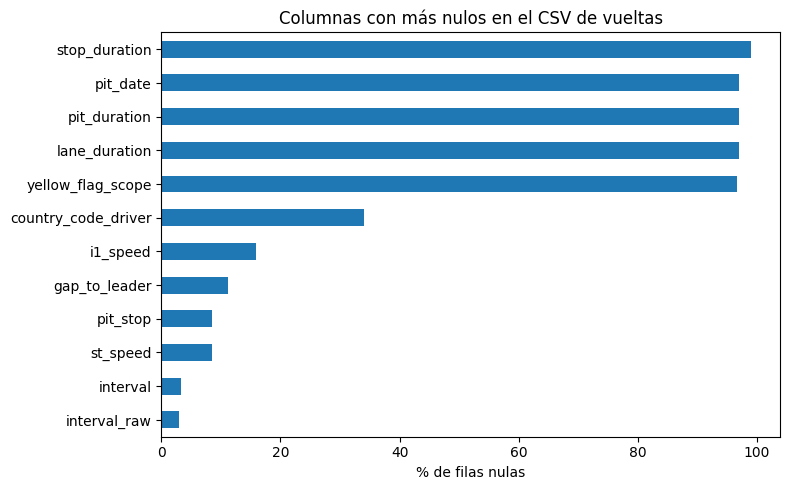

In [ ]:
ax = (nulos.head(12) * 100).sort_values().plot(kind="barh", figsize=(8, 5))
ax.set_title("Columnas con más nulos en el CSV de vueltas")
ax.set_xlabel("% de filas nulas")
plt.tight_layout()
plt.show()

In [ ]:
# Chequeamos con números las explicaciones de los nulos más altos.
es_pit = df["pit_stop"] == True
explicacion = pd.DataFrame({
    "stop_duration presente en vueltas con pit (%)": df[es_pit].groupby("season")["stop_duration"].apply(lambda s: s.notna().mean() * 100),
    "country_code_driver nulo (%)": df.groupby("season")["country_code_driver"].apply(lambda s: s.isna().mean() * 100),
    "pit_stop nulo (%)": df.groupby("season")["pit_stop"].apply(lambda s: s.isna().mean() * 100),
}).round(1)
display(explicacion)

print("pit_date nulo fuera de las vueltas con pit (%):", round(df.loc[~es_pit, "pit_date"].isna().mean() * 100, 1))
print("pit_date nulo en vueltas con pit (%):", round(df.loc[es_pit, "pit_date"].isna().mean() * 100, 1))
print("yellow_flag_scope nulo cuando no hay amarilla (%):",
      round(df.loc[~df["yellow_flag_active"], "yellow_flag_scope"].isna().mean() * 100, 1))
doblados = df.loc[df["gap_to_leader"].isna(), "gap_to_leader_raw"].str.contains("LAP", na=False)
print("gap_to_leader nulo porque el auto está doblado ('+N LAP'):", int(doblados.sum()), "de", int(df["gap_to_leader"].isna().sum()))
print("pit_duration == lane_duration en todas las paradas:", bool((df.loc[es_pit, "pit_duration"] == df.loc[es_pit, "lane_duration"]).all()))

,stop_duration presente en vueltas con pit (%),country_code_driver nulo (%),pit_stop nulo (%)
season,,,
2023,0.0,0.0,27.1
2024,18.1,0.0,0.0
2025,85.4,100.0,0.0


pit_date nulo fuera de las vueltas con pit (%): 100.0
pit_date nulo en vueltas con pit (%): 0.0
yellow_flag_scope nulo cuando no hay amarilla (%): 100.0
gap_to_leader nulo porque el auto está doblado ('+N LAP'): 6231 de 8622
pit_duration == lane_duration en todas las paradas: True


**Las tres columnas con más nulos son estructurales:**

| Columna | % nulos | Por qué |
|---|---|---|
| `stop_duration` | 98,9 % | Sólo existe en las vueltas con parada (3 %) y OpenF1 recién la mide desde 2024 (0 % en 2023, 18 % en 2024, 85 % en 2025). |
| `pit_date`, `pit_duration`, `lane_duration` | 97,0 % | Sólo existen en la vuelta en que hubo parada. Fuera de esas vueltas **tienen** que estar vacías. `pit_duration` y `lane_duration` son idénticas: una sobra. |
| `yellow_flag_scope` | 96,7 % | Sólo tiene valor cuando hay bandera amarilla. |

**Faltantes de verdad:**

| Columna | % nulos | Por qué |
|---|---|---|
| `country_code_driver` | 33,9 % | OpenF1 dejó de publicar el país del piloto en 2025 (100 % nulo en 2025, 0 % antes). No se usa. |
| `i1_speed` | 15,9 % | La trampa de velocidad intermedia no registró la vuelta. Es parejo entre temporadas. |
| `gap_to_leader` | 11,1 % | 6.2 mil casos son autos doblados (`"+1 LAP"`), que no tienen distancia en segundos; el resto quedó fuera de la tolerancia de 120 s del join. |
| `pit_stop` | 8,6 % | 6 carreras de 2023 sin datos de pits en OpenF1. Se quedan afuera del modelo 1 (no sabemos si hubo parada). |

In [ ]:
nulos_pits = pits.isna().mean().sort_values(ascending=False)
(nulos_pits[nulos_pits > 0].head(8) * 100).round(1).rename("% nulos (paradas)")

,% nulos (paradas)
yellow_flag_scope,88.6
stop_duration,63.8
country_code_driver,34.9
i1_speed,14.1
st_speed,11.5
gap_to_leader,10.1
interval,5.3
interval_raw,3.6


En el CSV de paradas el patrón es el mismo (los mismos nulos estructurales heredados de la vuelta) y **las columnas propias de la parada no tienen nulos**: `new_compound`, `new_stint_number` y `pit_stop_number` están completas.

## 1.4 Columnas sin información (constantes)

In [ ]:
constantes = df.columns[df.nunique() <= 1]
pd.DataFrame({"valor único": [df[c].dropna().iloc[0] for c in constantes],
              "% nulos": (df[constantes].isna().mean() * 100).round(1).values}, index=constantes)

,valor único,% nulos
session_name,Race,0.0
session_type,Race,0.0
weather_join_method,asof_previous,0.0
position_join_method,asof_previous,0.0
interval_join_method,asof_previous,0.0
yellow_flag_scope,Sector,96.7


Hay **6 columnas constantes**: `session_name` y `session_type` (siempre "Race", porque sólo bajamos carreras), los tres `*_join_method` (describen el método del join, siempre el mismo) y `yellow_flag_scope` (cuando tiene valor, siempre es "Sector"). **Se van del modelo**: una columna que no varía no puede explicar nada.

## 1.5 Duplicados de la clave

In [ ]:
pd.Series({
    "duplicados de la clave en vueltas": int(df.duplicated(CLAVE).sum()),
    "duplicados de la clave en paradas": int(pits.duplicated(CLAVE).sum()),
})

,0
duplicados de la clave en vueltas,0
duplicados de la clave en paradas,0


**Cero en las dos tablas.** La unidad de análisis está bien definida y el pipeline no duplica filas.

## 1.6 Distribución de la variable objetivo

Es el número más importante de esta entrega: si una clase se come todo, el modelo de la Entrega 3 arranca con un problema.

In [ ]:
objetivo_1 = df.loc[df["pit_data_available"] == True, "pit_stop"].value_counts(normalize=True)
objetivo_2 = pits["new_compound"].value_counts(normalize=True)

display((objetivo_1 * 100).round(2).rename("% de vueltas (pit_stop)"))
display(pd.DataFrame({"paradas": pits["new_compound"].value_counts(), "%": (objetivo_2 * 100).round(1)}))

,% de vueltas (pit_stop)
pit_stop,
False,96.7
True,3.3


,paradas,%
new_compound,,
HARD,1107,47.4
MEDIUM,656,28.1
SOFT,343,14.7
INTERMEDIATE,220,9.4
WET,7,0.3


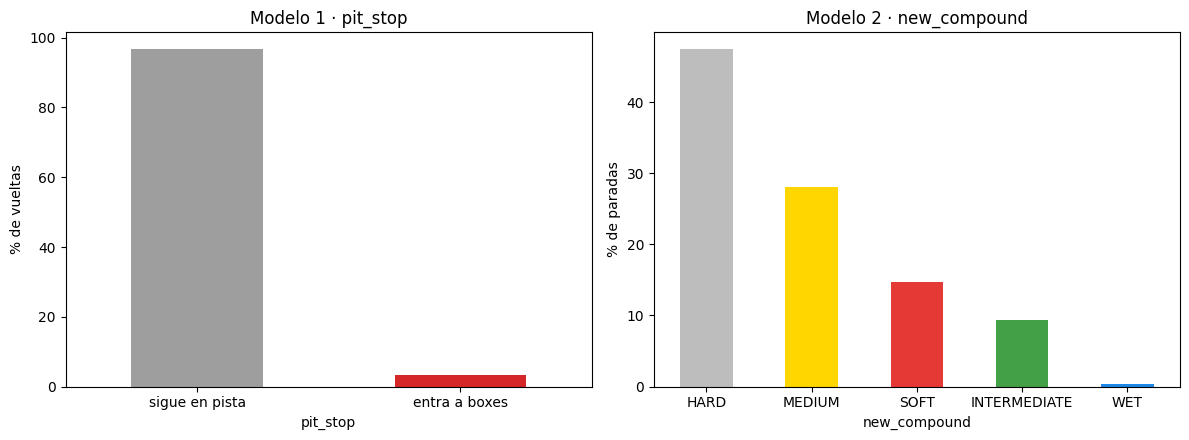

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

(objetivo_1 * 100).rename({False: "sigue en pista", True: "entra a boxes"}).plot(kind="bar", ax=ejes[0], color=["#9e9e9e", "#d62728"])
ejes[0].set_title("Modelo 1 · pit_stop")
ejes[0].set_ylabel("% de vueltas")
ejes[0].tick_params(axis="x", rotation=0)

colores = {"HARD": "#bdbdbd", "MEDIUM": "#ffd600", "SOFT": "#e53935", "INTERMEDIATE": "#43a047", "WET": "#1e88e5"}
(objetivo_2 * 100).plot(kind="bar", ax=ejes[1], color=[colores[c] for c in objetivo_2.index])
ejes[1].set_title("Modelo 2 · new_compound")
ejes[1].set_ylabel("% de paradas")
ejes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Modelo 1 (`pit_stop`): desbalance fuerte.** Sólo el **3,3 %** de las vueltas termina en boxes (2.333 de 70.746). Un modelo que siempre diga "no entra" acierta el 96,7 % y no sirve para nada. Decisiones para la Entrega 3:
- No medir con *accuracy*: usar recall, precisión y F1 de la clase "entra a boxes".
- Compensar el desbalance (pesos por clase o sobremuestreo sólo en entrenamiento).
- Separar entrenamiento y prueba **por carrera**, no por fila, para que vueltas de la misma carrera no queden en los dos lados.

**Modelo 2 (`new_compound`): desbalance moderado.** HARD se lleva el **47,4 %**, MEDIUM 28,1 %, SOFT 14,7 %, INTERMEDIATE 9,4 % y WET sólo **7 paradas (0,3 %)**. Con 7 casos no se puede aprender WET: la propuesta es unirlo con INTERMEDIATE en una clase "lluvia" (decisión pendiente del grupo).

## 1.7 Asimetría de las numéricas: ¿cuáles tienen cola larga?

In [ ]:
asimetria = df.select_dtypes("number").skew().sort_values()
asimetria[asimetria.abs() > 2].round(2).rename("asimetría")

,asimetría
st_speed,-2.94
pressure,-2.77
weather_timestamp_age_seconds,3.13
position_timestamp_age_seconds,3.24
lane_duration,5.02
pit_duration,5.02
rainfall,5.08
stop_duration,5.10
laps_missing_until_session_max,6.63
tyre_age_at_start,10.75


In [ ]:
df["lap_duration"].describe(percentiles=[0.5, 0.99]).round(1)

,lap_duration
count,77115.0
mean,94.4
std,66.6
min,67.0
50%,89.8
99%,156.3
max,2625.5


Tomamos |asimetría| > 2 como cola larga. Las que importan para el modelo:
- **`lap_duration` (25,7)**: la mediana es 90 s y el percentil 99 es 156 s, pero hay vueltas de hasta 2.625 s (bandera roja, safety car). **Se usa la vuelta anterior en escala logarítmica.**
- **`interval` (118,1) y `gap_to_leader` (38,9)**: la mayoría de los autos está a pocos segundos y unos pocos muy lejos. **Entran con `log1p`.**
- **`tyre_age_at_start` (10,8)**: casi siempre 0 (neumático nuevo); la cola son gomas usadas en clasificación. Sirve más como indicador "neumático usado sí/no".
- Las columnas de parada (`pit_duration`, `stop_duration`) y las de antigüedad de los joins (`*_timestamp_age_seconds`) también tienen cola larga, pero **no entran al modelo** (fuga o metadatos).

## 1.8 Resumen del perfil (los números a mano)

In [ ]:
base_pits = df[df["pit_data_available"] == True]
pd.Series({
    "filas × columnas (vueltas)": f"{df.shape[0]} × {df.shape[1]}",
    "filas × columnas (paradas)": f"{pits.shape[0]} × {pits.shape[1]}",
    "tipos (vueltas)": ", ".join(f"{k}: {v}" for k, v in df.dtypes.astype(str).value_counts().items()),
    "columna con más nulos": f"{nulos.index[0]} ({nulos.iloc[0]:.1%}, estructural)",
    "columnas constantes": len(constantes),
    "duplicados de la clave": int(df.duplicated(CLAVE).sum()),
    "objetivo 1: % vueltas con pit": f"{(base_pits['pit_stop'] == True).mean():.1%}",
    "objetivo 2: clase mayoritaria": f"{objetivo_2.index[0]} ({objetivo_2.iloc[0]:.1%})",
    "numéricas con |asimetría| > 2": int((asimetria.abs() > 2).sum()),
}).to_frame("valor")

,valor
filas × columnas (vueltas),77373 × 89
filas × columnas (paradas),2333 × 93
tipos (vueltas),"object: 31, float64: 26, bool: 21, int64: 11"
columna con más nulos,"stop_duration (98.9%, estructural)"
columnas constantes,6
duplicados de la clave,0
objetivo 1: % vueltas con pit,3.3%
objetivo 2: clase mayoritaria,HARD (47.4%)
numéricas con |asimetría| > 2,14


# 2. Chequeo de fuga en la vuelta del pit

Lo hacemos **antes** de las hipótesis porque decide qué versión de dos columnas clave (`current_compound` y `tyre_age`) podemos usar.

### Verificación de leakage - `compound`

Antes de dar por buena a `compound` como feature, hay que verificar **cuándo** se conoce ese valor: si en la fila de una vuelta `compound` representa el neumático con el que el piloto **está corriendo esa vuelta** (dato disponible antes de decidir el pit stop → válido como feature), o si en las vueltas donde `pit_stop = True` ya refleja el **neumático nuevo** colocado en esa parada (dato que recién se conoce después de la decisión → leakage).

La lógica del chequeo: en una parada real, el compuesto debería mantenerse igual al de la vuelta anterior (mismo neumático con el que llegó a boxes) y cambiar recién a partir de la vuelta siguiente (ya con el neumático nuevo). Si en cambio el compuesto de la vuelta del pit stop ya coincide con el de la vuelta siguiente, significa que la columna está guardando el neumático post-parada, y eso sería leakage.


In [ ]:
# Chequeo de leakage: ¿compound refleja el neumático ANTES o DESPUÉS del pit stop?

# Intentamos detectar automáticamente las columnas de piloto, carrera y vuelta.
cols_piloto = [c for c in df.columns if any(k in c.lower() for k in ["driver", "piloto"])]
cols_carrera = [c for c in df.columns if any(k in c.lower() for k in ["race", "session", "round", "carrera"])]
cols_vuelta = [c for c in df.columns if "lap" in c.lower() and "time" not in c.lower()]

print("Posibles columnas de piloto:", cols_piloto)
print("Posibles columnas de carrera/sesión:", cols_carrera)
print("Posibles columnas de vuelta:", cols_vuelta)
print("-" * 50)

# Ajustar estos tres nombres según lo que haya impreso arriba antes de correr el resto.
COL_PILOTO = cols_piloto[0] if cols_piloto else None
COL_CARRERA = cols_carrera[0] if cols_carrera else None
COL_VUELTA = cols_vuelta[0] if cols_vuelta else None
COL_COMPUESTO = "current_compound"

if not all([COL_PILOTO, COL_CARRERA, COL_VUELTA]):
    print("No se pudieron detectar automáticamente las tres columnas necesarias.")
    print("Completá COL_PILOTO, COL_CARRERA y COL_VUELTA a mano y volvé a correr esta celda.")
else:
    h3_leak = df[df["pit_data_available"] == True].copy()
    h3_leak = h3_leak.sort_values([COL_CARRERA, COL_PILOTO, COL_VUELTA])

    # compuesto de la vuelta anterior y de la vuelta siguiente, dentro del mismo piloto y carrera
    grp = h3_leak.groupby([COL_CARRERA, COL_PILOTO])[COL_COMPUESTO]
    h3_leak["compound_vuelta_anterior"] = grp.shift(1)
    h3_leak["compound_vuelta_siguiente"] = grp.shift(-1)

    stops = h3_leak[h3_leak["pit_stop"] == True].dropna(
        subset=["compound_vuelta_anterior", "compound_vuelta_siguiente"]
    )

    igual_a_anterior = (stops[COL_COMPUESTO] == stops["compound_vuelta_anterior"]).mean()
    igual_a_siguiente = (stops[COL_COMPUESTO] == stops["compound_vuelta_siguiente"]).mean()

    print(f"En vueltas con pit_stop, % que coincide con el compuesto de la vuelta ANTERIOR: {igual_a_anterior:.1%}")
    print(f"En vueltas con pit_stop, % que coincide con el compuesto de la vuelta SIGUIENTE: {igual_a_siguiente:.1%}")


Posibles columnas de piloto: ['driver_number', 'country_code_driver', 'driver_lap_count', 'driver_last_lap_observed']
Posibles columnas de carrera/sesión: ['session_key', 'session_name', 'session_type', 'session_date_start', 'session_max_lap_observed', 'laps_missing_until_session_max', 'session_status', 'race_control_event_count', 'race_control_recent_event', 'race_control_recent_event_timestamp', 'race_control_join_status']
Posibles columnas de vuelta: ['lap_number', 'lap_date_start', 'lap_duration', 'is_pit_out_lap', 'has_lap_duration', 'complete_lap_record', 'driver_lap_count', 'driver_last_lap_observed', 'session_max_lap_observed', 'laps_missing_until_session_max']
--------------------------------------------------
En vueltas con pit_stop, % que coincide con el compuesto de la vuelta ANTERIOR: 91.9%
En vueltas con pit_stop, % que coincide con el compuesto de la vuelta SIGUIENTE: 37.4%


El compuesto coincide con el de la vuelta anterior en el 91,9 % de las paradas, pero el porcentaje con la vuelta siguiente no sirve para decidir: muchas paradas ponen **el mismo** compuesto (MEDIUM → MEDIUM), y ahí coincide con las dos. La pregunta correcta es otra: **¿en cuántas vueltas con parada la fila ya tiene asignado el stint nuevo?** Si el stint cambió en la misma vuelta del pit, `current_compound` y `tyre_age` describen el neumático que se puso, no el que se sacó.

In [ ]:
h3_leak["stint_vuelta_anterior"] = h3_leak.groupby([COL_CARRERA, COL_PILOTO])["stint_number"].shift(1)
paradas = h3_leak[(h3_leak["pit_stop"] == True) & h3_leak["stint_vuelta_anterior"].notna()]
stint_nuevo = paradas["stint_number"] != paradas["stint_vuelta_anterior"]
compuesto_distinto = paradas[COL_COMPUESTO] != paradas["compound_vuelta_anterior"]

fuga = pd.DataFrame({
    "vueltas con pit": paradas.groupby("season").size(),
    "% con el stint nuevo ya asignado": stint_nuevo.groupby(paradas["season"]).mean() * 100,
    "% con otro compuesto que la vuelta anterior": compuesto_distinto.groupby(paradas["season"]).mean() * 100,
    "% con tyre_age = 0": (paradas["tyre_age"] == 0).groupby(paradas["season"]).mean() * 100,
})
fuga.loc["total"] = [len(paradas), stint_nuevo.mean() * 100, compuesto_distinto.mean() * 100, (paradas["tyre_age"] == 0).mean() * 100]
fuga.round(1)

,vueltas con pit,% con el stint nuevo ya asignado,% con otro compuesto que la vuelta anterior,% con tyre_age = 0
season,,,,
2023,657.0,10.4,4.6,6.8
2024,785.0,15.2,8.4,12.5
2025,802.0,24.9,10.6,13.6
total,2244.0,17.2,8.1,11.2


**Cómo leer este resultado:**

- Si el compuesto de la vuelta del pit coincide con el de la **vuelta anterior**, la fila guarda el neumático con el que el piloto llegó a boxes → no hay fuga.
- Si la fila de la vuelta del pit **ya tiene el stint nuevo**, `current_compound` y `tyre_age` están mostrando el neumático que se puso en esa parada → **hay fuga**: es la respuesta escrita de otra forma.

**Resultado obtenido:**

- En el **91,9 %** de las paradas el compuesto coincide con el de la vuelta anterior; en el **8,1 %** ya aparece el compuesto nuevo.
- Mirando el stint, en el **17,2 %** de las paradas la fila ya tiene asignado el stint nuevo, y en el **11,2 %** `tyre_age` vale 0 porque cuenta la edad de la goma recién puesta. Pasa en las tres temporadas y crece con los años (10,4 % en 2023, 15,2 % en 2024, 24,9 % en 2025).
- La causa está en OpenF1: en algunas paradas el stint nuevo empieza en la misma vuelta del pit (`lap_start = vuelta del pit`) y en otras en la siguiente. El pipeline asigna la vuelta al stint que empieza en ella.

**Conclusión (corrige la versión anterior de este notebook, que decía que no había fuga):** hay **fuga parcial** en `current_compound` y `tyre_age` del CSV de vueltas, justo en las filas que el modelo 1 tiene que acertar. La solución es usar lo que se sabe **al empezar la vuelta**, es decir, el valor de la vuelta anterior del mismo piloto:
- `compound_prev` en lugar de `current_compound`.
- `tyre_age_prev` en lugar de `tyre_age`.

En el CSV de paradas el pipeline ya corrige `current_compound` con el stint de entrada, así que para el modelo 2 esa columna sí sirve tal cual (pero `tyre_age` no, ver sección 0).

In [ ]:
# Base del modelo 1: vueltas de carreras con datos de pits, con las columnas "de la vuelta anterior".
base = df[df["pit_data_available"] == True].sort_values(CLAVE).copy()
base["pit"] = base["pit_stop"] == True
por_piloto = base.groupby(["session_key", "driver_number"])
base["tyre_age_prev"] = por_piloto["tyre_age"].shift(1)
base["compound_prev"] = por_piloto["current_compound"].shift(1)
base["stint_prev"] = por_piloto["stint_number"].shift(1)
base["lap_duration_prev"] = por_piloto["lap_duration"].shift(1)
base["race_frac"] = base["lap_number"] / base["session_max_lap_observed"]

pits["laps_remaining"] = pits["session_max_lap_observed"] - pits["lap_number"]

base[["tyre_age", "tyre_age_prev", "current_compound", "compound_prev"]].isna().sum().rename("nulos")

,nulos
tyre_age,175
tyre_age_prev,1274
current_compound,175
compound_prev,1274


Los nulos nuevos de las columnas `_prev` son estructurales: la primera vuelta de cada piloto no tiene vuelta anterior.

# 3. Fichas de hipótesis

Cada ficha tiene seis campos:

1. **Afirmación**: lo que creemos que pasa, en una oración.
2. **Tipo de pregunta**: si responde algo del **dominio** (la F1) o si **decide sobre una columna del modelo**.
3. **Qué espero ver**: el patrón que tendría que aparecer si la afirmación es cierta.
4. **Cómo lo mido**: el número que decide y contra qué corte del semáforo se compara.
5. **Resultado**: el número, su zona y el gráfico que lo acompaña. Si hace falta, hasta **dos movimientos** justificados por lo que se ve en el gráfico.
6. **Decisión**: confirmada, refutada o inconclusa, y qué hacemos con la columna.

**Semáforo** (cortes de la cátedra, se aplican sobre el valor absoluto):

| Medida | Cuándo se usa | rojo | amarillo | verde |
|---|---|---|---|---|
| Separación estandarizada | numérica vs. dos grupos | < 0,2 | 0,2 – 0,8 | > 0,8 |
| η² (eta cuadrado) | numérica vs. varios grupos | < 0,05 | 0,05 – 0,25 | > 0,25 |
| Correlación | dos numéricas | < 0,2 | 0,2 – 0,6 | > 0,6 |
| Brecha de proporciones | categórica vs. categórica | < 0,05 | 0,05 – 0,15 | > 0,15 |

Leemos verde como **confirmada**, amarillo como **señal moderada / inconclusa** y rojo como **refutada**.

# Hipótesis 1: edad del neumático y entrada a boxes

**Afirmación.** Los pilotos que entran a boxes tienden a hacerlo con neumáticos de mayor edad que aquellos que continúan en pista.

**Tipo de pregunta.** Decide sobre una columna del modelo 1: si `tyre_age` entra y en qué versión.

**Qué espero ver.** La edad del neumático (`tyre_age`) debería ser mayor en las vueltas donde `pit_stop = True` que en aquellas donde `pit_stop = False`.

**Cómo lo mido.** Es una hipótesis de **comparación entre dos grupos**, por lo que se utilizará la separación estandarizada como medida (verde > 0,8; rojo < 0,2) y un boxplot como apoyo visual.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Nos quedamos sólo con las vueltas donde la fuente de pits estaba disponible.
# Si pit_data_available=False, pit_stop queda nulo porque no sabemos si hubo parada.
h1 = df[df["pit_data_available"] == True].copy()

# Verificamos que en este subconjunto pit_stop tenga sólo True y False.
h1["pit_stop"].value_counts(dropna=False)

,count
pit_stop,
False,68413
True,2333


In [ ]:
# Revisamos cuántos valores faltantes tiene tyre_age antes de comparar los grupos.
h1["tyre_age"].isna().sum()

np.int64(175)

In [ ]:
# Separación estandarizada: distancia entre dos grupos
# expresada en unidades de desviación estándar.
def separacion(x, y):
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt(
        (x.std() ** 2 + y.std() ** 2) / 2
    )


# Cortes del semáforo definidos en el material de la cátedra.
CORTES = {
    "separacion": (0.2, 0.8),
    "eta2": (0.05, 0.25),
    "correlacion": (0.2, 0.6),
    "brecha": (0.05, 0.15)
}


def semaforo(valor, medida):
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


# η²: qué parte de la variación de una numérica se explica por los grupos de una categórica.
def eta2(valores, grupos):
    d = pd.DataFrame({"y": valores, "g": grupos}).dropna()
    media = d["y"].mean()
    entre = d.groupby("g")["y"].apply(lambda s: len(s) * (s.mean() - media) ** 2).sum()
    return entre / ((d["y"] - media) ** 2).sum()


# Brecha: diferencia entre la mayor y la menor proporción de una clase entre categorías.
def brecha(tasas):
    return tasas.max() - tasas.min()

In [ ]:
# Armamos los dos grupos que queremos comparar.
tyre_pit = h1.loc[h1["pit_stop"] == True, "tyre_age"]
tyre_no_pit = h1.loc[h1["pit_stop"] == False, "tyre_age"]

# Resumen descriptivo de ambos grupos.
pd.DataFrame({
    "entra a boxes": tyre_pit.describe(),
    "continúa en pista": tyre_no_pit.describe()
}).round(2)

,entra a boxes,continúa en pista
count,2333.00,68238.00
mean,15.51,13.52
std,11.32,10.50
min,0.00,0.00
25%,6.00,5.00
50%,16.00,11.00
75%,23.00,19.00
max,62.00,78.00


In [ ]:
# Calculamos el número que decide la hipótesis.
sep_h1 = separacion(tyre_pit, tyre_no_pit)

pd.Series({
    "separación": round(sep_h1, 3),
    "zona": semaforo(sep_h1, "separacion")
})

,0
separación,0.182
zona,rojo


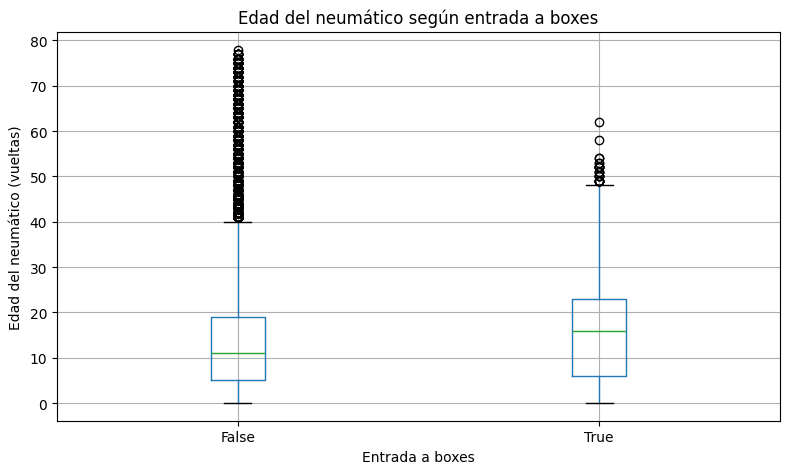

In [ ]:
# El gráfico explica visualmente el número obtenido.
h1.boxplot(
    column="tyre_age",
    by="pit_stop",
    figsize=(8, 5)
)

plt.title("Edad del neumático según entrada a boxes")
plt.suptitle("")
plt.xlabel("Entrada a boxes")
plt.ylabel("Edad del neumático (vueltas)")
plt.tight_layout()
plt.show()

### Resultado - Hipotesis 1

La edad del neumático presenta una diferencia descriptiva entre ambos grupos.

- En las vueltas con entrada a boxes, la edad media del neumático es de **15,51 vueltas** y la mediana es **16**.
- En las vueltas sin entrada a boxes, la edad media es de **13,52 vueltas** y la mediana es **11**.

Sin embargo, la **separación estandarizada es 0,182**, por lo que el resultado queda en **zona roja** según los cortes definidos.

El boxplot muestra una gran superposición entre las distribuciones de ambos grupos. Aunque los neumáticos son, en promedio, algo más antiguos cuando se produce una parada, la diferencia es pequeña en relación con la variabilidad existente dentro de los grupos.

### Movimiento 1 - Hipótesis 1: edad del neumático al empezar la vuelta

**Por qué lo hacemos (lo que se ve en el gráfico):** en el grupo "entra a boxes" la caja arranca muy abajo (mínimo 0, primer cuartil 6). Nadie entra a boxes con una goma recién puesta: esas filas son las del chequeo de fuga, donde la vuelta del pit ya tiene asignado el stint nuevo y `tyre_age` cuenta la edad de la goma que se acaba de poner.

**Qué cambiamos:** medimos la edad del neumático **al empezar la vuelta** (`tyre_age` de la vuelta anterior del mismo piloto), que es el dato que el equipo tiene cuando decide si llama al piloto.

In [ ]:
print("Vueltas con pit y tyre_age = 0:", int((tyre_pit == 0).sum()), "de", int(tyre_pit.notna().sum()))

h1 = h1.sort_values(["session_key", "driver_number", "lap_number"])
h1["tyre_age_prev"] = h1.groupby(["session_key", "driver_number"])["tyre_age"].shift(1)
edad_prev_pit = h1.loc[h1["pit_stop"] == True, "tyre_age_prev"]
edad_prev_no_pit = h1.loc[h1["pit_stop"] == False, "tyre_age_prev"]
sep_h1_mov = separacion(edad_prev_pit, edad_prev_no_pit)

pd.DataFrame({
    "mediana entra a boxes": [tyre_pit.median(), edad_prev_pit.median()],
    "mediana continúa": [tyre_no_pit.median(), edad_prev_no_pit.median()],
    "separación": [round(sep_h1, 3), round(sep_h1_mov, 3)],
    "zona": [semaforo(sep_h1, "separacion"), semaforo(sep_h1_mov, "separacion")],
}, index=["tyre_age (original)", "tyre_age_prev (movimiento 1)"])

Vueltas con pit y tyre_age = 0: 321 de 2333


,mediana entra a boxes,mediana continúa,separación,zona
tyre_age (original),16.0,11.0,0.182,rojo
tyre_age_prev (movimiento 1),17.0,11.0,0.409,amarillo


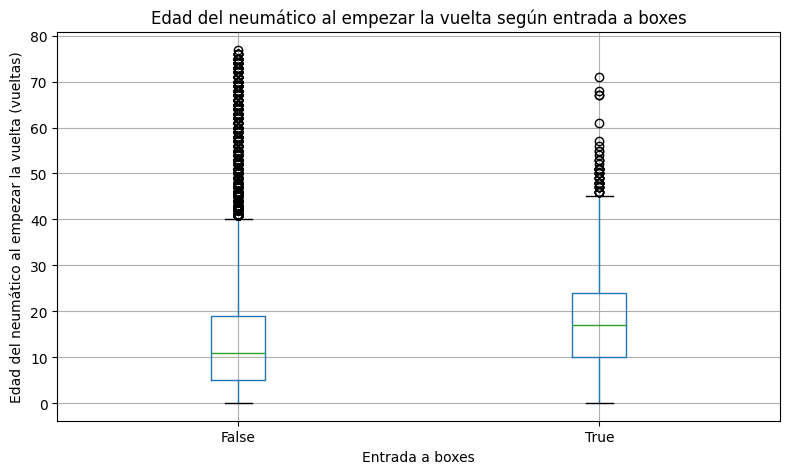

In [ ]:
h1.boxplot(column="tyre_age_prev", by="pit_stop", figsize=(8, 5))
plt.title("Edad del neumático al empezar la vuelta según entrada a boxes")
plt.suptitle("")
plt.xlabel("Entrada a boxes")
plt.ylabel("Edad del neumático al empezar la vuelta (vueltas)")
plt.tight_layout()
plt.show()

### Resultado del movimiento - Hipótesis 1

Con la edad del neumático al empezar la vuelta, la mediana del grupo que entra a boxes sube a **17 vueltas** contra **11** del que sigue, y la **separación estandarizada pasa de 0,182 (rojo) a 0,409 (amarillo)**. Las cajas todavía se superponen bastante: los pilotos paran con gomas de edades muy distintas según el compuesto, el circuito y lo que pasa en carrera.

### Decisión - Hipótesis 1

La hipótesis queda **inconclusa, con señal moderada (amarillo)**. La versión original daba roja, pero parte de esa "refutación" era la fuga: 321 vueltas con parada aparecían con neumático de edad 0.

Decisiones:
- **`tyre_age` sale** del modelo 1 (fuga parcial en la vuelta del pit).
- **`tyre_age_prev` entra** en su lugar: existe en el momento de decidir y separa más.
- La edad sola no alcanza para decidir la parada. En el modelado conviene combinarla con el compuesto (una HARD de 20 vueltas no es lo mismo que una SOFT de 20 vueltas).

# Hipótesis 2: posición del piloto y entrada a boxes

**Afirmación:** Los pilotos que ocupan posiciones más desfavorables en una determinada vuelta presentan una mayor frecuencia de entrada a boxes.

**Qué espero ver:** La distribución de la variable `position` debería ser diferente (específicamente con posiciones más retrasadas) en las vueltas donde `pit_stop = True` en comparación con aquellas donde `pit_stop = False`.

**Tipo de pregunta:** de dominio (¿la situación en carrera cambia la estrategia?), y además informa si `position` entra al modelo 1.

**Cómo lo mido:** comparación entre dos grupos → separación estandarizada (verde > 0,8; rojo < 0,2), con boxplot de apoyo.

**Por qué sirve para el TP:** Es una hipótesis de dominio, porque intenta relacionar la situación competitiva del piloto con una decisión estratégica. Además, `position` podría ser una candidata a feature para el modelo predictivo, ya que existe de manera previa a tomar la decisión de entrar a boxes y no es la respuesta en sí misma.

**Variables principales:**
* `position`
* `pit_stop`

In [ ]:
# Filtramos el dataset quedándonos con las vueltas donde hay datos de pits disponibles
# (Asumiendo que pit_data_available garantiza que pit_stop es True o False)
h2 = df[df["pit_data_available"] == True].copy()

# Revisamos cuántos valores faltantes tiene position antes de la comparación
nulos_pos = h2["position"].isna().sum()
print(f"Valores nulos en 'position': {nulos_pos}")

# Armamos los dos grupos que queremos comparar
pos_pit = h2.loc[h2["pit_stop"] == True, "position"]
pos_no_pit = h2.loc[h2["pit_stop"] == False, "position"]

# Resumen descriptivo de ambos grupos
pd.DataFrame({
    "entra a boxes": pos_pit.describe(),
    "continúa en pista": pos_no_pit.describe()
}).round(2)

Valores nulos en 'position': 47


,entra a boxes,continúa en pista
count,2331.00,68368.00
mean,8.83,9.81
std,5.27,5.42
min,1.00,1.00
25%,4.00,5.00
50%,9.00,10.00
75%,13.00,14.00
max,20.00,20.00


In [ ]:
# Calculamos la métrica de decisión para la hipótesis (separación estandarizada)
sep_h2 = separacion(pos_pit, pos_no_pit)

pd.Series({
    "separación": round(sep_h2, 3),
    "zona": semaforo(sep_h2, "separacion")
})

,0
separación,0.184
zona,rojo


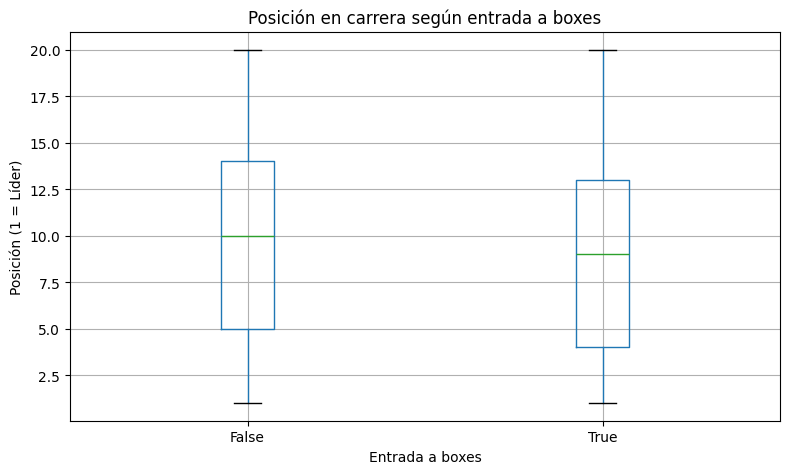

In [ ]:
# El gráfico de cajas apoya visualmente el número de separación obtenido
h2.boxplot(
    column="position",
    by="pit_stop",
    figsize=(8, 5)
)

plt.title("Posición en carrera según entrada a boxes")
plt.suptitle("")
plt.xlabel("Entrada a boxes")
plt.ylabel("Posición (1 = Líder)")
plt.tight_layout()
plt.show()

### Resultado - Hipótesis 2

La posición del piloto presenta una diferencia descriptiva mínima entre ambos grupos.   
- En las vueltas con entrada a boxes, la posición media es 8.83 y la mediana es 9.0.   
- En las vueltas sin entrada a boxes, la posición media es 9.81 y la mediana es 10.0.   

La métrica de separación estandarizada arroja un valor de 0.184, ubicando el resultado directamente en zona roja.   

El gráfico de cajas evidencia una superposición casi total de las distribuciones. Además, los datos revelan un comportamiento que contradice la afirmación original: los pilotos que entran a boxes se encuentran, en promedio, en posiciones ligeramente mejores (más cercanas al 1) que aquellos que deciden continuar en la pista

### Decisión - Hipótesis 2

La hipótesis queda refutada.

La variable `position` por sí sola no presenta una separación suficiente entre los grupos de `pit_stop = True` y `pit_stop = False`. El bajo valor de separación estandarizada, ubicado en zona roja, indica que la posición actual del piloto, considerada de manera aislada, no permite discriminar claramente entre las vueltas con y sin entrada a boxes.

Por lo tanto, aunque `position` no resulta un buen discriminador univariado, no debe descartarse automáticamente como variable predictiva. La tendencia observada puede estar relacionada con otros factores estratégicos que no se consideran en esta hipótesis. Su posible utilidad en combinación con otras variables deberá evaluarse posteriormente en el modelado multivariado.


# Hipótesis 3: Compuesto actual y entrada a boxes

**Afirmación:** La frecuencia de entrada a boxes varía según el compuesto de neumático que está utilizando el piloto.

**Qué espero ver:** Que la proporción (o porcentaje) de vueltas que terminan en una entrada a boxes (`pit_stop = True`) sea significativamente distinta dependiendo del tipo de compuesto que el auto tenga calzado en ese momento (ej. Soft, Medium, Hard, Wet, etc.).

**Tipo de pregunta:** decide sobre una columna del modelo 1 (`current_compound`).

**Cómo lo mido:** categórica vs. categórica → **brecha** entre la mayor y la menor proporción de vueltas con parada (verde > 0,15; rojo < 0,05), con gráfico de barras.

**Por qué sirve para el TP:** Es una hipótesis muy alineada con el objetivo del proyecto, ya que busca determinar si el tipo de neumático actual aporta información valiosa para decidir si corresponde realizar una parada. Al existir en el momento previo a la decisión, `current_compound` es una candidata a feature para el modelo predictivo.

**Variables principales:**
* `current_compound` (Categórica)
* `pit_stop` (Booleana)


In [ ]:
# H3 - Compuesto actual y entrada a boxes

h3_tabla = pd.crosstab(
    df["current_compound"],
    df["pit_stop"],
    normalize="index"
) * 100

h3_tabla = h3_tabla.rename(
    columns={
        False: "pit_stop = False (%)",
        True: "pit_stop = True (%)"
    }
)

h3_tabla

pit_stop,pit_stop = False (%),pit_stop = True (%)
current_compound,,
HARD,97.878394,2.121606
INTERMEDIATE,94.486943,5.513057
MEDIUM,95.990789,4.009211
SOFT,95.340321,4.659679
WET,81.578947,18.421053


In [ ]:
# Diferencia entre la mayor y menor proporción de pit_stop

max_pit = h3_tabla["pit_stop = True (%)"].max()
min_pit = h3_tabla["pit_stop = True (%)"].min()

diferencia_h3 = max_pit - min_pit

print(f"Mayor proporción de pit_stop: {max_pit:.2f}%")
print(f"Menor proporción de pit_stop: {min_pit:.2f}%")
print(f"Diferencia: {diferencia_h3:.2f} puntos porcentuales")

brecha_h3 = diferencia_h3 / 100
print(f"Brecha: {brecha_h3:.3f} → zona {semaforo(brecha_h3, 'brecha')}")

# Cuántas vueltas hay detrás de cada porcentaje
df.loc[df["pit_data_available"] == True, "current_compound"].value_counts().rename("vueltas")

Mayor proporción de pit_stop: 18.42%
Menor proporción de pit_stop: 2.12%
Diferencia: 16.30 puntos porcentuales
Brecha: 0.163 → zona verde


,vueltas
current_compound,
HARD,32334
MEDIUM,26489
SOFT,7919
INTERMEDIATE,3791
WET,38


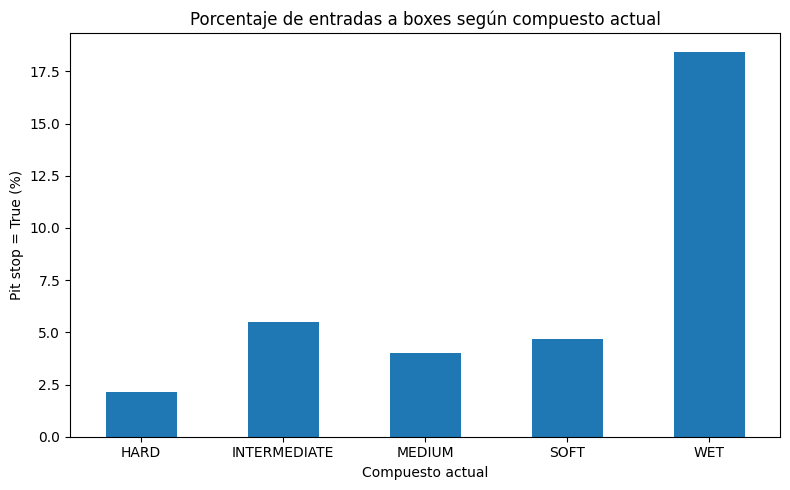

In [ ]:
import matplotlib.pyplot as plt

h3_tabla["pit_stop = True (%)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Porcentaje de entradas a boxes según compuesto actual")
plt.xlabel("Compuesto actual")
plt.ylabel("Pit stop = True (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Resultados - Hipótesis 3

La proporción de entradas a boxes presenta diferencias según el compuesto actual del neumático.

El porcentaje de vueltas con `pit_stop = True` fue de **2,12% para HARD, 5,51% para INTERMEDIATE, 4,01% para MEDIUM, 4,66% para SOFT y 18,42% para WET**.

La diferencia entre el compuesto con mayor y menor proporción de entradas a boxes es de **16,30 puntos porcentuales**, siendo WET el compuesto con mayor porcentaje de entradas a boxes. Como proporción, la **brecha es 0,163 → zona verde**.

Pero el gráfico engaña: la barra de WET, la que genera toda la brecha, está hecha con **38 vueltas**, contra decenas de miles de HARD o MEDIUM. Y además `current_compound` tiene la fuga de la sección 2. Por eso hacemos dos movimientos.

### Movimiento 1 - Hipótesis 3: compuesto al empezar la vuelta

**Por qué:** el chequeo de fuga mostró que en el 8,1 % de las paradas `current_compound` ya es el compuesto nuevo. Usamos `compound_prev`, el compuesto con el que el piloto empieza la vuelta.

In [ ]:
tasas_h3_prev = base.groupby("compound_prev")["pit"].agg(["mean", "size"]).rename(columns={"mean": "% con pit", "size": "vueltas"})
tasas_h3_prev["% con pit"] = tasas_h3_prev["% con pit"] * 100
brecha_h3_mov1 = brecha(tasas_h3_prev["% con pit"] / 100)
display(tasas_h3_prev.round(2))
print(f"Brecha con compound_prev: {brecha_h3_mov1:.3f} → zona {semaforo(brecha_h3_mov1, 'brecha')}")

,% con pit,vueltas
compound_prev,,
HARD,2.00,31773
INTERMEDIATE,5.98,3744
MEDIUM,3.99,26200
SOFT,4.28,7717
WET,26.32,38


Brecha con compound_prev: 0.243 → zona verde


### Movimiento 2 - Hipótesis 3: sólo compuestos de seco

**Por qué:** en el gráfico la brecha la genera una sola barra (WET) con muy pocas vueltas. La decisión de parar con lluvia depende del clima, no del compuesto. Repetimos la medida sólo con SOFT, MEDIUM y HARD, que son el 90 % de las vueltas.

Brecha sólo en seco: 0.023 → zona rojo


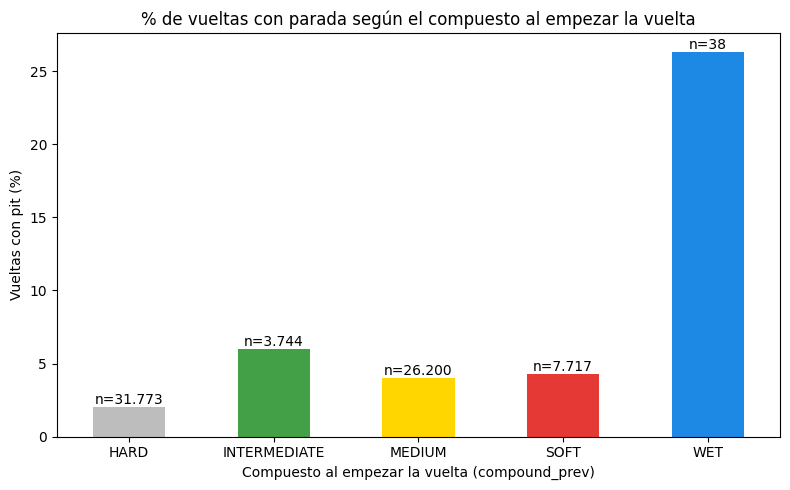

In [ ]:
seco = tasas_h3_prev.loc[["SOFT", "MEDIUM", "HARD"]]
brecha_h3_mov2 = brecha(seco["% con pit"] / 100)
print(f"Brecha sólo en seco: {brecha_h3_mov2:.3f} → zona {semaforo(brecha_h3_mov2, 'brecha')}")

ax = tasas_h3_prev["% con pit"].plot(kind="bar", figsize=(8, 5),
                                   color=["#bdbdbd", "#43a047", "#ffd600", "#e53935", "#1e88e5"])
for x, (tasa, n) in enumerate(zip(tasas_h3_prev["% con pit"], tasas_h3_prev["vueltas"])):
    ax.annotate(f"n={n:,}".replace(",", "."), (x, tasa), ha="center", va="bottom")
plt.title("% de vueltas con parada según el compuesto al empezar la vuelta")
plt.xlabel("Compuesto al empezar la vuelta (compound_prev)")
plt.ylabel("Vueltas con pit (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Resultado de los movimientos - Hipótesis 3

| Versión | Brecha | Zona |
|---|---|---|
| `current_compound`, todos los compuestos | 0,163 | verde |
| `compound_prev`, todos los compuestos (movimiento 1) | 0,243 | verde, pero sostenido por 38 vueltas de WET |
| `compound_prev`, sólo seco (movimiento 2) | 0,023 | rojo |

En seco, la probabilidad de parar va de **2,0 % con HARD a 4,3 % con SOFT**. En términos relativos es el doble, pero como diferencia absoluta es chica frente a la base de 3,3 %.

### Decisión - Hipótesis 3

La hipótesis queda **inconclusa** (antes figuraba como confirmada, pero no tenía zona y la brecha dependía de muy pocas vueltas con WET).

- Con todos los compuestos la brecha es verde, pero la sostienen las pocas vueltas con WET/INTERMEDIATE, que dependen de la lluvia.
- En seco, la brecha es roja (0,023): el compuesto solo casi no cambia la probabilidad de parar en una vuelta.

Decisiones:
- **`current_compound` sale** del modelo 1 por fuga parcial; **`compound_prev` entra** en su lugar (codificada con one-hot).
- Es más útil combinada con la edad del neumático (H1) que sola.
- Para resolver la parte inconclusa haría falta medir la **edad a la que se para con cada compuesto**, no sólo la frecuencia de paradas.

# Hipótesis 4: safety car y compuesto elegido en la parada

**Afirmación.** Cuando la parada se hace con el safety car en pista, los equipos montan un compuesto más blando (menos HARD) que en una parada normal.

**Tipo de pregunta.** De dominio (¿el safety car cambia la estrategia de neumáticos?) y también decide sobre una columna del modelo 2: si `safety_car_active` entra para predecir `new_compound`.

**Qué espero ver.** Que la proporción de paradas con `new_compound = HARD` sea menor cuando `safety_car_active = True`.

**Cómo lo mido.** Categórica vs. categórica → **brecha** de la proporción de HARD entre paradas con y sin safety car (verde > 0,15; rojo < 0,05), con barras apiladas. Se usa el CSV de paradas (`pits`), que es la base del modelo 2.

**Variables principales:** `safety_car_active` (eventos de dirección de carrera anteriores a la vuelta) y `new_compound`.

In [ ]:
def tabla_por_safety_car(datos):
    grupo = datos["safety_car_active"].map({False: "sin safety car", True: "con safety car"})
    tabla = pd.crosstab(grupo, datos["new_compound"], normalize="index") * 100
    tabla["paradas"] = grupo.value_counts()
    return tabla


def brecha_hard(tabla):
    return (tabla.loc["sin safety car", "HARD"] - tabla.loc["con safety car", "HARD"]) / 100


def barras_compuesto(tabla, titulo):
    orden = [c for c in ["SOFT", "MEDIUM", "HARD", "INTERMEDIATE", "WET"] if c in tabla.columns]
    tabla[orden].plot(kind="barh", stacked=True, figsize=(9, 4), color=[colores[c] for c in orden])
    plt.title(titulo)
    plt.xlabel("% de paradas")
    plt.ylabel("")
    plt.legend(title="new_compound", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


tabla_h4 = tabla_por_safety_car(pits)
brecha_h4 = brecha_hard(tabla_h4)
display(tabla_h4.round(1))
pd.Series({"brecha HARD": round(brecha_h4, 3), "zona": semaforo(brecha_h4, "brecha")})

new_compound,HARD,INTERMEDIATE,MEDIUM,SOFT,WET,paradas
safety_car_active,,,,,,
con safety car,25.7,27.9,27.5,19.0,0.0,269
sin safety car,50.3,7.0,28.2,14.1,0.3,2064


,0
brecha HARD,0.246
zona,verde


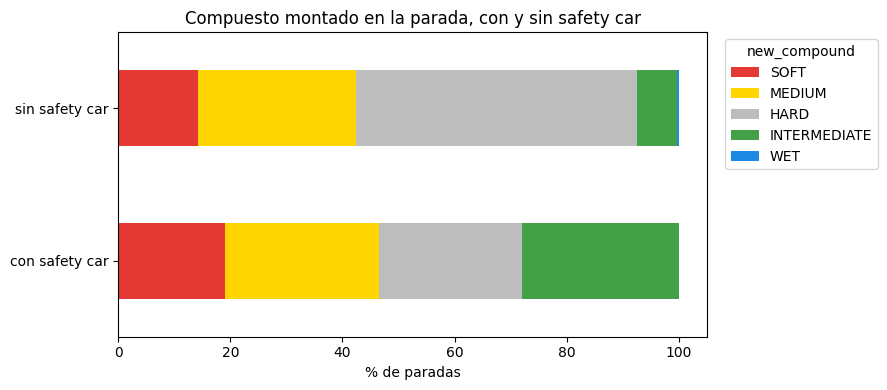

In [ ]:
barras_compuesto(tabla_h4, "Compuesto montado en la parada, con y sin safety car")

### Resultado - Hipótesis 4

Con safety car, el **25,7 %** de las paradas monta HARD; sin safety car, el **50,3 %**. La **brecha es 0,246 → zona verde**.

Pero el gráfico muestra algo que ensucia la comparación: en las paradas con safety car, INTERMEDIATE ocupa el **27,9 %**, contra 7,0 % sin safety car. Muchos safety car pasan en carreras con lluvia, y ahí no se elige entre blando y duro sino entre seco y lluvia. Parte de la brecha podría ser lluvia y no safety car.

### Movimiento 1 - Hipótesis 4: sólo paradas de seco

**Por qué (lo que se ve en el gráfico):** la barra con safety car tiene mucho INTERMEDIATE. Nos quedamos con las paradas sin lluvia (`rainfall = 0`) que entran y salen con SOFT, MEDIUM o HARD.

In [ ]:
seco_h4 = pits[(pits["rainfall"] == 0)
               & pits["current_compound"].isin(["SOFT", "MEDIUM", "HARD"])
               & pits["new_compound"].isin(["SOFT", "MEDIUM", "HARD"])]
tabla_h4_seco = tabla_por_safety_car(seco_h4)
brecha_h4_mov1 = brecha_hard(tabla_h4_seco)
display(tabla_h4_seco.round(1))
print(f"Brecha HARD sólo en seco: {brecha_h4_mov1:.3f} → zona {semaforo(brecha_h4_mov1, 'brecha')}")
print("Mediana de vueltas restantes en la parada:")
seco_h4.groupby("safety_car_active")["laps_remaining"].median()

new_compound,HARD,MEDIUM,SOFT,paradas
safety_car_active,,,,
con safety car,35.1,37.8,27.1,188
sin safety car,56.5,29.2,14.3,1810


Brecha HARD sólo en seco: 0.214 → zona verde
Mediana de vueltas restantes en la parada:


,laps_remaining
safety_car_active,
False,34.0
True,25.0


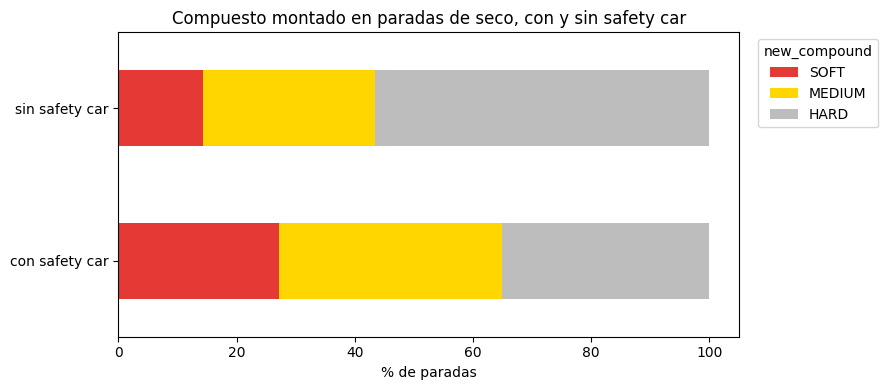

In [ ]:
barras_compuesto(tabla_h4_seco, "Compuesto montado en paradas de seco, con y sin safety car")

### Movimiento 2 - Hipótesis 4: sin las últimas 15 vueltas

**Por qué:** en seco, las paradas con safety car pasan más cerca del final (mediana de 25 vueltas restantes contra 34). Cerca del final lo lógico es un blando porque no hace falta durar, así que la brecha podría ser por el momento de la carrera y no por el safety car. Repetimos la medida sólo con las paradas a las que les quedan más de 15 vueltas.

In [ ]:
sin_final_h4 = seco_h4[seco_h4["laps_remaining"] > 15]
tabla_h4_mov2 = tabla_por_safety_car(sin_final_h4)
brecha_h4_mov2 = brecha_hard(tabla_h4_mov2)
display(tabla_h4_mov2.round(1))
print(f"Brecha HARD en seco y con más de 15 vueltas por delante: {brecha_h4_mov2:.3f} → zona {semaforo(brecha_h4_mov2, 'brecha')}")
print("Carreras distintas con paradas bajo safety car:", pits.loc[pits["safety_car_active"], "session_key"].nunique())

new_compound,HARD,MEDIUM,SOFT,paradas
safety_car_active,,,,
con safety car,33.8,40.7,25.5,145
sin safety car,59.6,29.3,11.1,1671


Brecha HARD en seco y con más de 15 vueltas por delante: 0.258 → zona verde
Carreras distintas con paradas bajo safety car: 20


### Resultado de los movimientos - Hipótesis 4

| Versión | HARD sin SC | HARD con SC | Brecha | Zona |
|---|---|---|---|---|
| Todas las paradas | 50,3 % | 25,7 % | 0,246 | verde |
| Sólo seco (movimiento 1) | 56,5 % | 35,1 % | 0,214 | verde |
| Seco y más de 15 vueltas por delante (movimiento 2) | 59,6 % | 33,8 % | 0,258 | verde |

La brecha **se mantiene verde** después de sacar la lluvia y el final de carrera. Lo que ocupa el lugar del HARD es el blando: en seco, SOFT pasa de **14,3 % a 27,1 %** y MEDIUM de 29,2 % a 37,8 % cuando hay safety car.

Aclaración: las 269 paradas con safety car vienen de **20 carreras**, y en un mismo safety car paran muchos pilotos a la vez. No son 269 decisiones independientes, así que el número es menos firme de lo que parece.

### Decisión - Hipótesis 4

La hipótesis queda **confirmada** (verde después de los dos movimientos).

- **`safety_car_active` entra** al modelo 2 y existe al predecir: se calcula con los eventos de dirección de carrera anteriores a la vuelta. Ya entraba al modelo 1 (con safety car la tasa de parada se duplica).
- El safety car no sólo cambia **cuándo** se para, también **qué** se pone: con la parada más barata, los equipos se animan a un compuesto más blando.
- Para la Entrega 3: al separar entrenamiento y prueba **por carrera**, las paradas de un mismo safety car quedan del mismo lado y no inflan el resultado.

## Resumen de las cuatro fichas

In [ ]:
pd.DataFrame([
    ["H1", "Se para con neumáticos más viejos", "columna (tyre_age)", "separación", f"{sep_h1:.3f} → {sep_h1_mov:.3f}",
     semaforo(sep_h1_mov, "separacion"), "1: edad al empezar la vuelta", "Inconclusa · entra tyre_age_prev"],
    ["H2", "Se para más desde posiciones retrasadas", "dominio", "separación", f"{sep_h2:.3f}",
     semaforo(sep_h2, "separacion"), "—", "Refutada · position entra a prueba"],
    ["H3", "La frecuencia de parada cambia con el compuesto", "columna (current_compound)", "brecha",
     f"{brecha_h3:.3f} → {brecha_h3_mov1:.3f} → {brecha_h3_mov2:.3f}", semaforo(brecha_h3_mov2, "brecha"),
     "1: compuesto al empezar la vuelta · 2: sólo seco", "Inconclusa · entra compound_prev"],
    ["H4", "Con safety car se monta un compuesto más blando", "dominio + columna (safety_car_active)", "brecha",
     f"{brecha_h4:.3f} → {brecha_h4_mov1:.3f} → {brecha_h4_mov2:.3f}", semaforo(brecha_h4_mov2, "brecha"),
     "1: sólo seco · 2: sin las últimas 15 vueltas", "Confirmada · safety_car_active entra al modelo 2"],
], columns=["ficha", "afirmación", "tipo", "medida", "número", "zona_final", "movimientos", "decisión"]).set_index("ficha")

,afirmación,tipo,medida,número,zona_final,movimientos,decisión
ficha,,,,,,,
H1,Se para con neumáticos más viejos,columna (tyre_age),separación,0.182 → 0.409,amarillo,1: edad al empezar la vuelta,Inconclusa · entra tyre_age_prev
H2,Se para más desde posiciones retrasadas,dominio,separación,0.184,rojo,—,Refutada · position entra a prueba
H3,La frecuencia de parada cambia con el compuesto,columna (current_compound),brecha,0.163 → 0.243 → 0.023,rojo,1: compuesto al empezar la vuelta · 2: sólo seco,Inconclusa · entra compound_prev
H4,Con safety car se monta un compuesto más blando,dominio + columna (safety_car_active),brecha,0.246 → 0.214 → 0.258,verde,1: sólo seco · 2: sin las últimas 15 vueltas,Confirmada · safety_car_active entra al modelo 2


# 4. Tabla de columnas candidatas

Una fila por columna que pensamos darle al modelo (o que descartamos). La última columna es el **chequeo de fuga**: ¿esa columna existiría en el momento de predecir? Si la respuesta ya está adentro, no es una feature.

Para cada candidata calculamos su número contra el objetivo de su modelo, con la misma medida que en las fichas:
- **Modelo 1** (`pit_stop`, base `base`): separación para numéricas, brecha de % de vueltas con parada para categóricas (categorías con al menos 200 vueltas).
- **Modelo 2** (`new_compound`, base `pits`): η² para numéricas; para categóricas, la mayor brecha de proporción de un compuesto entre categorías (con al menos 30 paradas).

In [ ]:
def medir(columna, modelo, tipo):
    if modelo == 1:
        if tipo == "num":
            return "separacion", separacion(base.loc[base["pit"], columna], base.loc[~base["pit"], columna])
        tasas = base.groupby(columna)["pit"].agg(["mean", "size"])
        return "brecha", brecha(tasas.loc[tasas["size"] >= 200, "mean"])
    if tipo == "num":
        return "eta2", eta2(pits[columna], pits["new_compound"])
    tabla = pd.crosstab(pits[columna], pits["new_compound"], normalize="index")
    tabla = tabla[pits[columna].value_counts().reindex(tabla.index) >= 30]
    return "brecha", (tabla.max() - tabla.min()).max()


candidatas = [
    # columna, modelo, tipo, qué mide, decisión, ¿existiría al predecir?
    ("tyre_age_prev", 1, "num", "Edad del neumático al empezar la vuelta", "Entra (reemplaza a tyre_age)", "Sí — se conoce al cerrar la vuelta anterior"),
    ("tyre_age", 1, "num", "Edad del neumático del stint asignado a la vuelta", "Sale", "No siempre — en el 17 % de las paradas ya es la goma nueva"),
    ("compound_prev", 1, "cat", "Compuesto al empezar la vuelta", "Entra (one-hot, reemplaza a current_compound)", "Sí"),
    ("current_compound", 1, "cat", "Compuesto del stint asignado a la vuelta", "Sale del modelo 1", "No siempre — en el 8 % de las paradas ya es el compuesto nuevo"),
    ("stint_prev", 1, "num", "Tandas hechas hasta la vuelta anterior", "Entra", "Sí"),
    ("race_frac", 1, "num", "Avance de la carrera (vuelta / vueltas totales)", "Entra", "Sí, con las vueltas programadas en lugar de las observadas"),
    ("position", 1, "num", "Posición en carrera (H2)", "Entra a prueba", "Sí — último dato anterior a la vuelta"),
    ("gap_to_leader", 1, "num", "Segundos al líder", "Entra a prueba, en log1p + indicador de doblado", "Sí — último dato anterior a la vuelta"),
    ("interval", 1, "num", "Segundos al auto de adelante", "Entra a prueba, en log1p", "Sí — último dato anterior a la vuelta"),
    ("lap_duration_prev", 1, "num", "Tiempo de la vuelta anterior (ritmo / degradación)", "Entra a prueba, en escala logarítmica (la cola larga tapa la señal)", "Sí"),
    ("lap_duration", 1, "num", "Tiempo de la vuelta actual", "Sale", "No — la vuelta del pit incluye la entrada a boxes y se conoce al terminarla"),
    ("track_temperature", 1, "num", "Temperatura de pista", "Entra a prueba", "Sí — último registro de clima anterior"),
    ("rainfall", 1, "cat", "Si está lloviendo", "Entra (con lluvia la tasa de parada se duplica: 3,2 % → 6,8 %)", "Sí — último registro de clima anterior"),
    ("safety_car_active", 1, "cat", "Safety car en pista", "Entra (con SC la tasa de parada se duplica: 3,1 % → 6,2 %)", "Sí — eventos de dirección de carrera anteriores a la vuelta"),
    ("virtual_safety_car_active", 1, "cat", "Virtual safety car", "Entra (3,3 % → 7,0 %)", "Sí — eventos anteriores a la vuelta"),
    ("circuit_short_name", 1, "cat", "Circuito", "Entra a prueba (one-hot)", "Sí"),
    ("team_name", 1, "cat", "Equipo", "Entra a prueba", "Sí"),
    ("current_compound", 2, "cat", "Compuesto con el que entra a boxes (ya corregido en el CSV de paradas)", "Entra", "Sí"),
    ("rainfall", 2, "cat", "Si está lloviendo", "Entra", "Sí"),
    ("safety_car_active", 2, "cat", "Safety car en pista (H4)", "Entra", "Sí — eventos de dirección de carrera anteriores a la vuelta"),
    ("laps_remaining", 2, "num", "Vueltas que faltan", "Entra a prueba", "Sí, con las vueltas programadas"),
    ("pit_stop_number", 2, "num", "Número de parada (1.ª, 2.ª…)", "Entra", "Sí — el equipo sabe cuántas paradas hizo"),
    ("track_temperature", 2, "num", "Temperatura de pista", "Entra", "Sí"),
    ("circuit_short_name", 2, "cat", "Circuito", "Entra (one-hot)", "Sí"),
]

filas = []
for columna, modelo, tipo, que_mide, decision, existe in candidatas:
    medida, valor = medir(columna, modelo, tipo)
    nombre_medida = {"separacion": "separación", "eta2": "η²", "brecha": "brecha"}[medida]
    filas.append([columna, modelo, que_mide, nombre_medida, round(valor, 3), semaforo(valor, medida), decision, existe])

descartadas = [
    ("new_compound", "1", "Compuesto montado en la parada", "Objetivo del modelo 2; sale del modelo 1", "No — se decide en la parada"),
    ("pit_duration, lane_duration, stop_duration, pit_date", "1 y 2", "Duración y hora de la parada", "Sale (fuga)", "No — se miden durante la parada"),
    ("new_stint_number, new_tyre_age_at_start", "2", "Datos del neumático nuevo", "Sale (fuga)", "No — describen lo que se montó"),
    ("tyre_age (en el CSV de paradas)", "2", "Edad del neumático en la vuelta del pit", "Sale (321 filas con la edad de la goma nueva)", "No siempre"),
    ("driver_lap_count, driver_last_lap_observed, laps_missing_until_session_max, possible_early_exit", "1 y 2", "Cuántas vueltas completó el piloto", "Sale (fuga)", "No — se conocen cuando termina la carrera"),
    ("session_name, session_type, *_join_method, yellow_flag_scope", "1 y 2", "Constantes", "Sale", "—"),
    ("country_code_driver", "1 y 2", "País del piloto", "Sale (34 % nulo y sin relación con la decisión)", "Sí, pero no aporta"),
    ("race_control_recent_event", "1 y 2", "Último mensaje de dirección de carrera (texto libre)", "Sale (resumido en las banderas)", "Sí"),
    ("session_key, meeting_key, driver_number, timestamps", "1 y 2", "Identificadores y horarios", "Sale (sólo para ordenar y separar por carrera)", "Sí, pero no son features"),
]
for columna, modelo, que_mide, decision, existe in descartadas:
    filas.append([columna, modelo, que_mide, "—", None, "—", decision, existe])

tabla_candidatas = pd.DataFrame(filas, columns=["columna", "modelo", "qué mide", "medida", "número", "zona", "decisión", "¿existiría al predecir?"])
pd.set_option("display.max_colwidth", None)
tabla_candidatas

,columna,modelo,qué mide,medida,número,zona,decisión,¿existiría al predecir?
0,tyre_age_prev,1,Edad del neumático al empezar la vuelta,separación,0.409,amarillo,Entra (reemplaza a tyre_age),Sí — se conoce al cerrar la vuelta anterior
1,tyre_age,1,Edad del neumático del stint asignado a la vuelta,separación,0.182,rojo,Sale,No siempre — en el 17 % de las paradas ya es la goma nueva
2,compound_prev,1,Compuesto al empezar la vuelta,brecha,0.040,rojo,"Entra (one-hot, reemplaza a current_compound)",Sí
3,current_compound,1,Compuesto del stint asignado a la vuelta,brecha,0.034,rojo,Sale del modelo 1,No siempre — en el 8 % de las paradas ya es el compuesto nuevo
4,stint_prev,1,Tandas hechas hasta la vuelta anterior,separación,0.350,amarillo,Entra,Sí
5,race_frac,1,Avance de la carrera (vuelta / vueltas totales),separación,0.228,amarillo,Entra,"Sí, con las vueltas programadas en lugar de las observadas"
6,position,1,Posición en carrera (H2),separación,0.184,rojo,Entra a prueba,Sí — último dato anterior a la vuelta
7,gap_to_leader,1,Segundos al líder,separación,0.045,rojo,"Entra a prueba, en log1p + indicador de doblado",Sí — último dato anterior a la vuelta
8,interval,1,Segundos al auto de adelante,separación,0.050,rojo,"Entra a prueba, en log1p",Sí — último dato anterior a la vuelta
9,lap_duration_prev,1,Tiempo de la vuelta anterior (ritmo / degradación),separación,0.016,rojo,"Entra a prueba, en escala logarítmica (la cola larga tapa la señal)",Sí


**Cómo leer la tabla:**
- Casi todas las candidatas del modelo 1 dan **rojo o amarillo solas**, y es esperable: con 3,3 % de paradas ninguna variable sola decide. Las más fuertes son `tyre_age_prev` (0,409), `stint_prev` (0,350) y `race_frac` (0,228). La zona sirve para ordenar prioridades; "entra a prueba" quiere decir que se evalúa en el modelado y sale si no suma. Se descarta de entrada sólo por **fuga**, por **constante** o por **falta de datos**.
- En el modelo 2 hay señal más clara: el **compuesto con el que se entra** (brecha 0,586, verde) y el **circuito** (0,808, verde; parte de esa brecha la ponen las carreras con lluvia) pesan mucho más que las **vueltas restantes** (η² 0,034, rojo). El **safety car** (H4) también suma: con SC se monta menos HARD.
- Las decisiones más importantes salen del chequeo de fuga: `tyre_age`, `current_compound` y `lap_duration` de la vuelta actual **se reemplazan por su valor de la vuelta anterior**, y todo lo que describe la parada o el final de la carrera **sale**.
- `race_frac` y `laps_remaining` usan `session_max_lap_observed`, que se calcula al final de la carrera. En carreras normales coincide con las vueltas programadas, que sí se conocen antes; en las acortadas no. Para la Entrega 3 hay que reemplazarlo por las vueltas programadas.

# 5. Cierre: lo que hay que saber explicar

**Qué cambió desde la Entrega 1.** Se agregó `f1_silver_pit_stops.csv`: 2.333 paradas × 93 columnas, con `new_compound` completo y 0 claves duplicadas. La pregunta no cambió, pero ahora tiene dos objetivos medibles: `pit_stop` (¿paro?) y `new_compound` (¿qué pongo?).

**Variable objetivo y distribución.** `pit_stop`: 3,3 % de vueltas con parada, desbalance fuerte. `new_compound`: HARD 47,4 %, WET 0,3 % (7 paradas).

**Por qué hay nulos donde hay nulos.** Los tres peores son estructurales: datos de la parada (sólo existen si hubo parada), `stop_duration` (además sólo desde 2024) y `yellow_flag_scope` (sólo con amarilla). Faltantes de verdad: `country_code_driver` (OpenF1 no lo publica en 2025), `i1_speed` (trampa de velocidad) y `gap_to_leader` (autos doblados).

**Qué hipótesis nos salió mal y qué hicimos.** H2 (posición) quedó refutada: los que paran están, si algo, un poco más adelante. H1 daba roja por una fuga: al usar la edad al empezar la vuelta pasó a amarilla. H3 parecía verde, pero la sostenía el WET con pocas vueltas: en seco es roja.

**Qué columna descartamos por fuga y cuándo se completa en la realidad.** `tyre_age` y `current_compound` del CSV de vueltas: en el 17 % de las paradas ya muestran la goma nueva, que se conoce **después** de parar. También `pit_duration`/`stop_duration` (se miden durante la parada) y `laps_missing_until_session_max` (se conoce cuando termina la carrera).

**Qué quedó inconcluso y qué haría falta.**
- H3: medir la edad a la que se para con cada compuesto, o una curva de degradación por compuesto y circuito.
- Qué compuesto de seco elegir (modelo 2): el compuesto de entrada (verde) y el circuito (verde) ayudan, las vueltas restantes no (rojo). Falta construir la regla de "usar dos compuestos en seco" (qué compuestos ya usó el piloto en la carrera) y separar cuánto de la señal del circuito es lluvia.
- Reemplazar `session_max_lap_observed` por las vueltas programadas de cada carrera.
- Pipeline: recalcular `tyre_age` en el CSV de paradas y alinear el stint de la vuelta del pit con el de entrada.